# Momento de Retroalimentación: Módulo 5 Implementación de un modelo de deep learning (Portafolio Implementación)

Saúl Caballero Castor

A01751748

13 de noviembre del 2026

## 1. Introducción

En este proyecto se entrena una CNN que, a partir de una foto de una cámara fija, dice si hay un auto y dónde está con un bounding box. Se comparan dos versiones: una CNN entrenada desde cero (v1) y transfer learning con MobileNetV2 (v2).

In [2]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

/Users/scaballero/Downloads/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow: 2.20.0
GPU: []


## 2. Datos

Dataset propio con 1181 fotos de una cámara fija en el estacionamiento D del Tec, de día y de noche. Los autos se anotaron a mano en CVAT y se exportó en formato COCO 1.0, donde cada caja es `[x, y, ancho, alto]` en pixeles.

In [3]:
DATA_DIR = Path("M5")
coco_path = DATA_DIR / "annotations" / "instances_default.json"
img_dir = DATA_DIR / "images" / "default"

IMG_SIZE = 224
BATCH_SIZE = 32

with open(coco_path) as f:
    coco = json.load(f)

print("Categorías:", [c["name"] for c in coco["categories"]])
print("Imágenes:", len(coco["images"]))
print("Anotaciones:", len(coco["annotations"]))

Categorías: ['car']
Imágenes: 1181
Anotaciones: 1405


### Análisis

Imágenes sin autos: 7
Imágenes con un auto: 984
Imágenes con más de un auto: 190


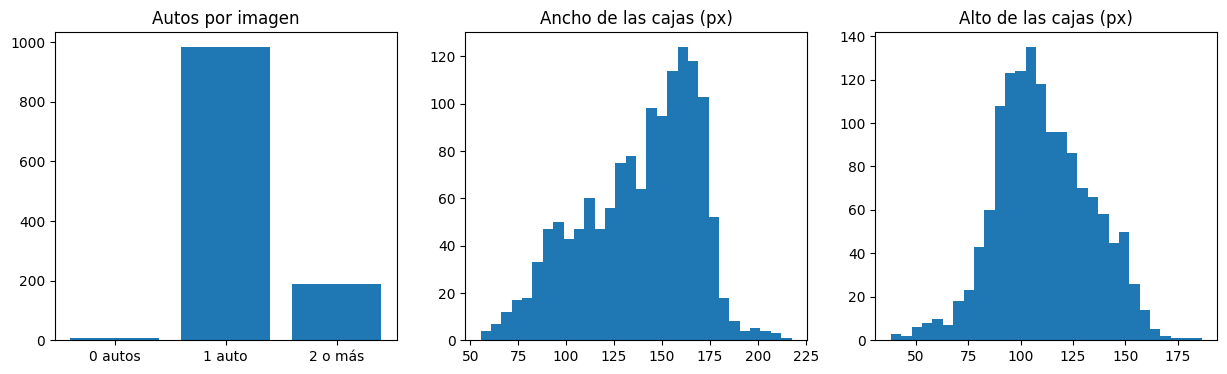

In [4]:
cajas_por_imagen = {img["id"]: [] for img in coco["images"]}
for ann in coco["annotations"]:
    cajas_por_imagen[ann["image_id"]].append(ann["bbox"])

autos_por_imagen = [len(c) for c in cajas_por_imagen.values()]
sin_autos = autos_por_imagen.count(0)
un_auto = autos_por_imagen.count(1)
varios = sum(n > 1 for n in autos_por_imagen)

print("Imágenes sin autos:", sin_autos)
print("Imágenes con un auto:", un_auto)
print("Imágenes con más de un auto:", varios)

anchos = [b[2] for c in cajas_por_imagen.values() for b in c]
altos = [b[3] for c in cajas_por_imagen.values() for b in c]

plt.figure(figsize=(15, 4))
plt.subplot(131)
plt.bar(["0 autos", "1 auto", "2 o más"], [sin_autos, un_auto, varios])
plt.title("Autos por imagen")
plt.subplot(132)
plt.hist(anchos, bins=30)
plt.title("Ancho de las cajas (px)")
plt.subplot(133)
plt.hist(altos, bins=30)
plt.title("Alto de las cajas (px)")
plt.show()

### Preparación

El modelo predice una sola caja por imagen, así que solo se usan las fotos con 0 o 1 auto. Las 190 fotos con varios autos se quitan porque no tienen una sola caja correcta.

Por cada foto se guarda si hay auto (1 o 0) y la caja normalizada entre 0 y 1 como `[x_min, y_min, x_max, y_max]`. En las fotos vacías la caja es `[0, 0, 0, 0]` y no se usa en la pérdida.

In [5]:
rutas, cajas, hay_auto = [], [], []

# Ordenadas por nombre, que es el orden de captura
for img in sorted(coco["images"], key=lambda i: i["file_name"]):
    anotaciones = cajas_por_imagen[img["id"]]
    if len(anotaciones) > 1:
        continue

    W, H = img["width"], img["height"]
    if len(anotaciones) == 1:
        x, y, w, h = anotaciones[0]
        cajas.append([x / W, y / H, (x + w) / W, (y + h) / H])
        hay_auto.append(1.0)
    else:
        cajas.append([0.0, 0.0, 0.0, 0.0])
        hay_auto.append(0.0)
    rutas.append(str(img_dir / img["file_name"]))

cajas = np.array(cajas, dtype=np.float32)
hay_auto = np.array(hay_auto, dtype=np.float32)
print("Imágenes usadas:", len(rutas))

Imágenes usadas: 991


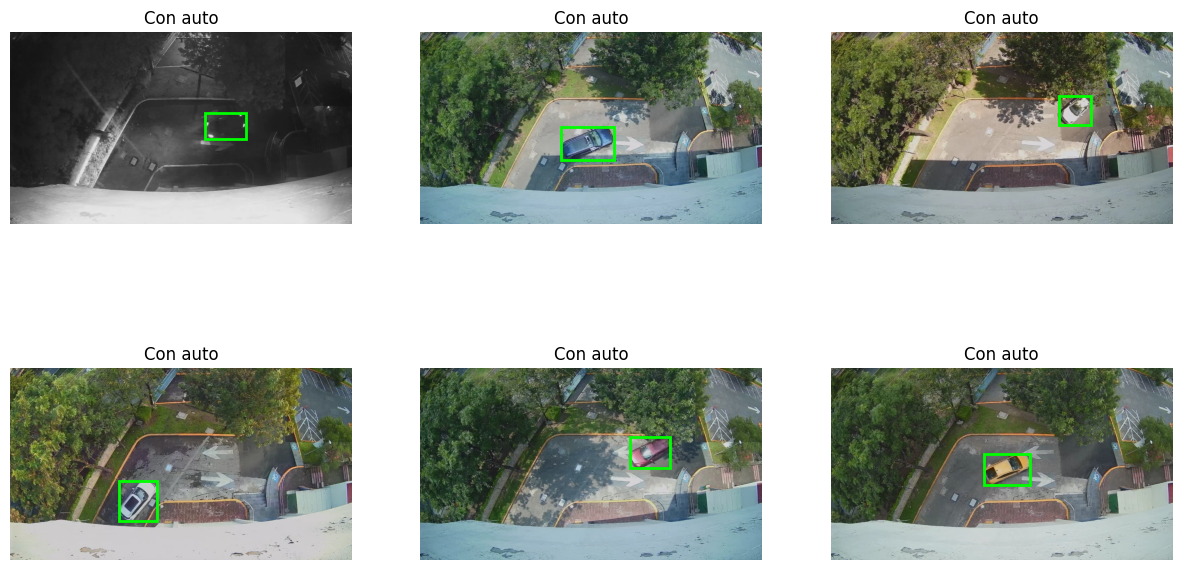

In [6]:
def dibujar_caja(ax, caja, W, H, color):
    x1, y1, x2, y2 = caja
    ax.add_patch(patches.Rectangle((x1 * W, y1 * H), (x2 - x1) * W, (y2 - y1) * H,
                                   linewidth=2, edgecolor=color, facecolor="none"))

plt.figure(figsize=(15, 8))
for k, i in enumerate(random.sample(range(len(rutas)), 6)):
    img = plt.imread(rutas[i])
    ax = plt.subplot(2, 3, k + 1)
    ax.imshow(img)
    if hay_auto[i] == 1:
        dibujar_caja(ax, cajas[i], img.shape[1], img.shape[0], "lime")
    ax.set_title("Con auto" if hay_auto[i] == 1 else "Sin auto")
    ax.axis("off")
plt.show()

### Separación

Las fotos salen de un video, así que fotos seguidas son casi iguales. Para que no haya fotos casi idénticas en entrenamiento y validación, se separa en bloques consecutivos: 70% entrenamiento, 15% validación y 15% prueba.

In [7]:
n = len(rutas)
fin_train = int(n * 0.70)
fin_val = int(n * 0.85)

rutas_train, cajas_train, auto_train = rutas[:fin_train], cajas[:fin_train], hay_auto[:fin_train]
rutas_val, cajas_val, auto_val = rutas[fin_train:fin_val], cajas[fin_train:fin_val], hay_auto[fin_train:fin_val]
rutas_test, cajas_test, auto_test = rutas[fin_val:], cajas[fin_val:], hay_auto[fin_val:]

for nombre, a in [("Entrenamiento", auto_train), ("Validación", auto_val), ("Prueba", auto_test)]:
    print(f"{nombre}: {len(a)} imágenes, {int(a.sum())} con auto")

Entrenamiento: 693 imágenes, 686 con auto
Validación: 149 imágenes, 149 con auto
Prueba: 149 imágenes, 149 con auto


Solo hay 7 fotos sin auto y todas quedaron en entrenamiento, así que en validación y prueba todas las fotos tienen auto.

### Preprocesamiento

Las imágenes se redimensionan a 224x224 y se normalizan entre 0 y 1. El dataset también regresa un peso por muestra para que la caja solo cuente en la pérdida cuando hay auto.

In [8]:
def cargar(ruta, caja, auto):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    objetivos = {"auto": auto, "bbox": caja}
    pesos = {"auto": 1.0, "bbox": auto}
    return img, objetivos, pesos


def crear_dataset(rutas_ds, cajas_ds, auto_ds, entrenamiento=False, aumentar=None):
    ds = tf.data.Dataset.from_tensor_slices((rutas_ds, cajas_ds, auto_ds))
    ds = ds.map(cargar, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(1000)
    if aumentar is not None:
        ds = ds.map(aumentar, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = crear_dataset(rutas_train, cajas_train, auto_train, entrenamiento=True)
val_ds = crear_dataset(rutas_val, cajas_val, auto_val)
test_ds = crear_dataset(rutas_test, cajas_test, auto_test)

## 3. Desarrollo del modelo

### v1

CNN con 4 bloques `Conv2D` + `MaxPooling2D` y una capa densa de 512. Tiene dos salidas: `auto`, la probabilidad de que haya un auto, y `bbox`, las 4 coordenadas de la caja.

In [9]:
def crear_cnn():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    for filtros in [32, 64, 128, 256]:
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)

    auto = layers.Dense(1, activation="sigmoid", name="auto")(x)
    bbox = layers.Dense(4, activation="sigmoid", name="bbox")(x)
    return tf.keras.Model(inputs, {"auto": auto, "bbox": bbox})


model_v1 = crear_cnn()
model_v1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 28, 28,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 28, 28,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 14, 14,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 50176)     │          0 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │ 25,690,624 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ auto (Dense)        │ (None, 1)         │        513 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox (Dense)        │ (None, 4)         │      2,052 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,081,605 (99.49 MB)

 Trainable params: 26,081,605 (99.49 MB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento

Binary crossentropy para `auto` y MSE para `bbox`. El MSE se multiplica por 10 porque es mucho más chico que la otra pérdida. Se usa EarlyStopping con paciencia de 5 y ModelCheckpoint para quedarse con el mejor modelo.

In [10]:
os.makedirs("modelos", exist_ok=True)

def compilar(modelo, lr):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss={"auto": "binary_crossentropy", "bbox": "mse"},
        loss_weights={"auto": 1.0, "bbox": 10.0},
        metrics={"auto": ["accuracy"], "bbox": ["mae"]},
    )

def callbacks(nombre):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5),
        tf.keras.callbacks.ModelCheckpoint(f"modelos/{nombre}.keras", monitor="val_loss",
                                           save_best_only=True),
    ]

compilar(model_v1, 1e-4)
history_v1 = model_v1.fit(train_ds, epochs=40, validation_data=val_ds, callbacks=callbacks("v1"))

# Mejor modelo guardado
model_v1 = tf.keras.models.load_model("modelos/v1.keras")

Epoch 1/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 245ms/step - auto_accuracy: 0.8331 - auto_loss: 0.2188 - bbox_loss: 0.0216 - bbox_mae: 0.1297 - loss: 0.4346 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.0054 - val_bbox_loss: 0.0188 - val_bbox_mae: 0.1109 - val_loss: 0.1899
Epoch 2/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 240ms/step - auto_accuracy: 0.9888 - auto_loss: 0.0680 - bbox_loss: 0.0210 - bbox_mae: 0.1282 - loss: 0.2778 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.0023 - val_bbox_loss: 0.0162 - val_bbox_mae: 0.1031 - val_loss: 0.1610
Epoch 3/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 246ms/step - auto_accuracy: 0.9900 - auto_loss: 0.0629 - bbox_loss: 0.0198 - bbox_mae: 0.1263 - loss: 0.2614 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.0052 - val_bbox_loss: 0.0122 - val_bbox_mae: 0.0912 - val_loss: 0.1247
Epoch 4/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 244ms/step - auto_accuracy: 0.9931 - auto_loss: 0.0502 - bbox_loss: 0.0128 - bbox_mae: 0.0958 - loss: 0.1785 - val_auto_accuracy: 1.0000 - val_auto_loss: 0

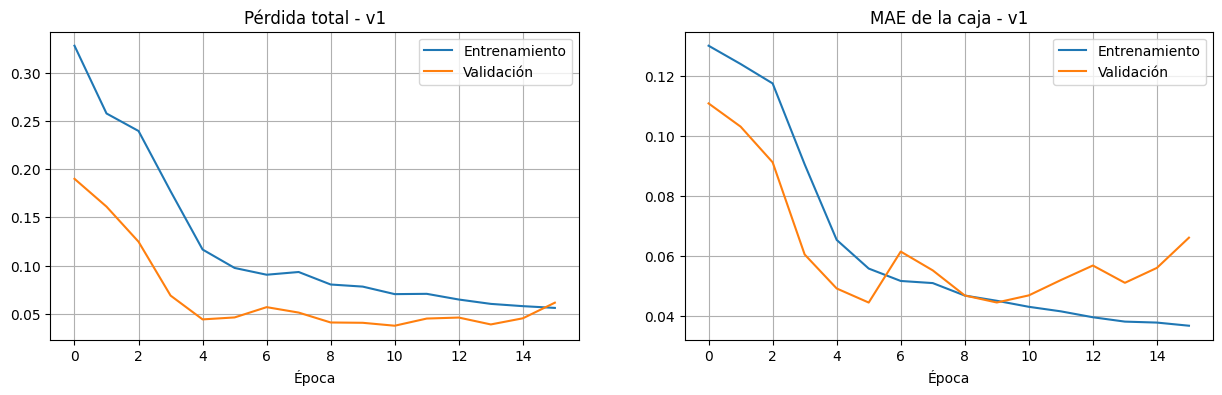

In [11]:
def graficar(history, titulo):
    plt.figure(figsize=(15, 4))
    plt.subplot(121)
    plt.plot(history.history["loss"], label="Entrenamiento")
    plt.plot(history.history["val_loss"], label="Validación")
    plt.title(f"Pérdida total - {titulo}")
    plt.xlabel("Época")
    plt.legend()
    plt.grid(True)
    plt.subplot(122)
    plt.plot(history.history["bbox_mae"], label="Entrenamiento")
    plt.plot(history.history["val_bbox_mae"], label="Validación")
    plt.title(f"MAE de la caja - {titulo}")
    plt.xlabel("Época")
    plt.legend()
    plt.grid(True)
    plt.show()

graficar(history_v1, "v1")

### Evaluación

Además del MAE se calcula el IoU entre la caja predicha y la real (1 es perfecta, 0 es que no se tocan). Una caja se toma como correcta si su IoU es de al menos 0.5. Las métricas de la caja solo se calculan en fotos con auto.

In [12]:
def iou(a, b):
    x1 = np.maximum(a[:, 0], b[:, 0])
    y1 = np.maximum(a[:, 1], b[:, 1])
    x2 = np.minimum(a[:, 2], b[:, 2])
    y2 = np.minimum(a[:, 3], b[:, 3])
    interseccion = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return interseccion / np.maximum(area_a + area_b - interseccion, 1e-6)


def evaluar(modelo, ds, cajas_reales, auto_real):
    pred = modelo.predict(ds, verbose=0)
    prob = pred["auto"][:, 0]
    cajas_pred = np.clip(pred["bbox"], 0, 1)

    con_auto = auto_real == 1
    ious = iou(cajas_pred[con_auto], cajas_reales[con_auto])
    return {
        "exactitud": round(float(np.mean((prob >= 0.5) == con_auto)), 3),
        "MAE caja": round(float(np.mean(np.abs(cajas_pred[con_auto] - cajas_reales[con_auto]))), 4),
        "IoU promedio": round(float(np.mean(ious)), 3),
        "% IoU >= 0.5": round(float(np.mean(ious >= 0.5) * 100), 1),
    }

metricas_v1 = evaluar(model_v1, val_ds, cajas_val, auto_val)
metricas_v1

{'exactitud': 1.0,
 'MAE caja': 0.0468,
 'IoU promedio': 0.312,
 '% IoU >= 0.5': 21.5}

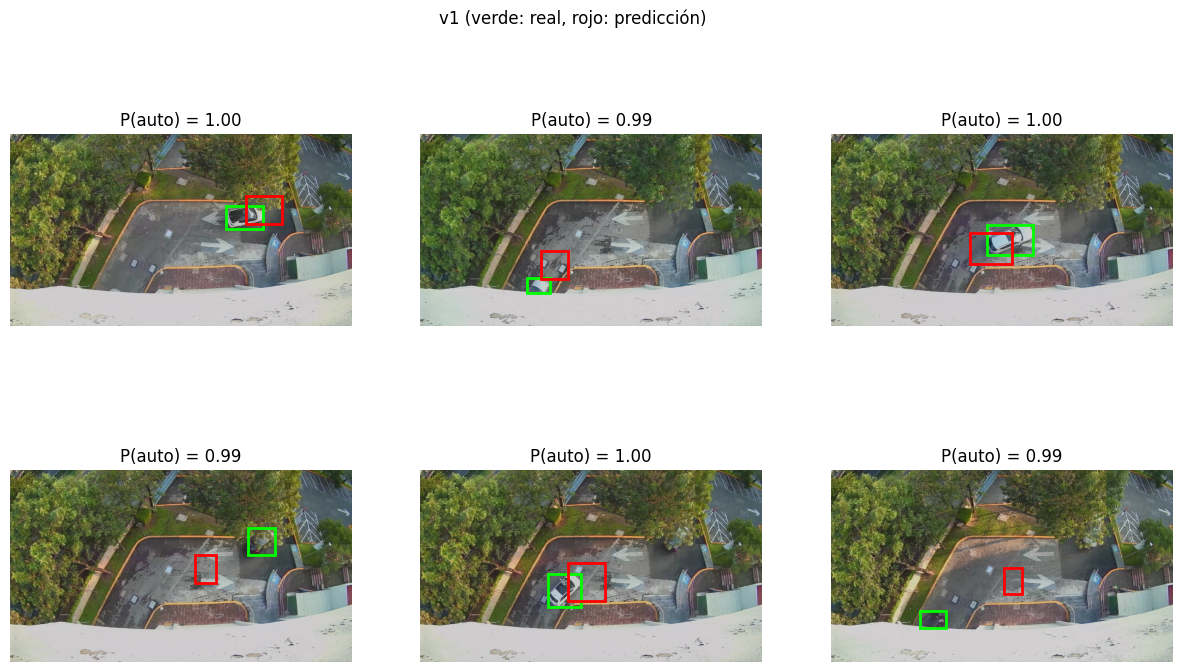

In [13]:
def predecir(modelo, ruta):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    pred = modelo.predict(img[None], verbose=0)
    return float(pred["auto"][0, 0]), np.clip(pred["bbox"][0], 0, 1)


def mostrar_predicciones(modelo, rutas_img, cajas_reales, auto_real, titulo):
    plt.figure(figsize=(15, 8))
    indices = np.linspace(0, len(rutas_img) - 1, 6).astype(int)
    for k, i in enumerate(indices):
        prob, caja = predecir(modelo, rutas_img[i])
        img = plt.imread(rutas_img[i])
        H, W = img.shape[:2]
        ax = plt.subplot(2, 3, k + 1)
        ax.imshow(img)
        if auto_real[i] == 1:
            dibujar_caja(ax, cajas_reales[i], W, H, "lime")
        if prob >= 0.5:
            dibujar_caja(ax, caja, W, H, "red")
        ax.set_title(f"P(auto) = {prob:.2f}")
        ax.axis("off")
    plt.suptitle(f"{titulo} (verde: real, rojo: predicción)")
    plt.show()

mostrar_predicciones(model_v1, rutas_val, cajas_val, auto_val, "v1")

## 4. Ajuste del modelo

### Problemas de v1

En la gráfica de v1 el MAE de validación llega a su mínimo entre las épocas 5 y 9 y después sube, mientras el de entrenamiento sigue bajando, lo que indica sobreajuste. En validación el IoU promedio fue de 0.312 y solo el 21.5% de las cajas tuvo IoU ≥ 0.5. En los ejemplos la caja suele caer cerca del auto, pero desplazada.

Casi todos los parámetros de v1 (25.7 de 26 millones) están entre `Flatten` y la capa de 512, y son demasiados para 693 fotos de entrenamiento.

### Cambios en v2

- Transfer learning con MobileNetV2 congelado, como en el notebook 08.
- Una convolución 1x1 antes de `Flatten` que baja de 1280 a 64 canales, para tener menos parámetros sin perder la posición.
- Dropout de 0.3.
- Aumento de datos con volteo horizontal (volteando también la caja), brillo y contraste, como en el notebook 04.


In [14]:
def aumentar(img, objetivos, pesos):
    caja = objetivos["bbox"]
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        caja = tf.stack([1 - caja[2], caja[1], 1 - caja[0], caja[3]])
    img = tf.image.random_brightness(img, 0.15)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, {"auto": objetivos["auto"], "bbox": caja}, pesos

train_aug_ds = crear_dataset(rutas_train, cajas_train, auto_train, entrenamiento=True, aumentar=aumentar)

In [15]:
def crear_transfer():
    base = tf.keras.applications.MobileNetV2(weights="imagenet", include_top=False,
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)  # MobileNetV2 usa pixeles entre -1 y 1
    x = base(x, training=False)                     # 7 x 7 x 1280
    x = layers.Conv2D(64, 1, activation="relu")(x)  # 7 x 7 x 64
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    auto = layers.Dense(1, activation="sigmoid", name="auto")(x)
    bbox = layers.Dense(4, activation="sigmoid", name="bbox")(x)
    return tf.keras.Model(inputs, {"auto": auto, "bbox": bbox})


model_v2 = crear_transfer()
model_v2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 7, 7, 64)  │     81,984 │ mobilenetv2_1.00… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3136)      │          0 │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    803,072 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ auto (Dense)        │ (None, 1)         │        257 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox (Dense)        │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,144,325 (11.99 MB)

 Trainable params: 886,341 (3.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
compilar(model_v2, 1e-3)
history_v2 = model_v2.fit(train_aug_ds, epochs=40, validation_data=val_ds, callbacks=callbacks("v2"))

model_v2 = tf.keras.models.load_model("modelos/v2.keras")

Epoch 1/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - auto_accuracy: 0.9434 - auto_loss: 0.2322 - bbox_loss: 0.1107 - bbox_mae: 0.2849 - loss: 1.3402 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.1090 - val_bbox_loss: 0.0164 - val_bbox_mae: 0.1042 - val_loss: 0.2729
Epoch 2/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - auto_accuracy: 0.9937 - auto_loss: 0.0683 - bbox_loss: 0.0224 - bbox_mae: 0.1260 - loss: 0.2930 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.0334 - val_bbox_loss: 0.0130 - val_bbox_mae: 0.0911 - val_loss: 0.1625
Epoch 3/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - auto_accuracy: 0.9943 - auto_loss: 0.0484 - bbox_loss: 0.0156 - bbox_mae: 0.1029 - loss: 0.2045 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.0249 - val_bbox_loss: 0.0077 - val_bbox_mae: 0.0659 - val_loss: 0.0997
Epoch 4/40
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - auto_accuracy: 0.9873 - auto_loss: 0.0511 - bbox_loss: 0.0116 - bbox_mae: 0.0921 - loss: 0.1676 - val_auto_accuracy: 1.0000 - val_auto_loss: 0.01

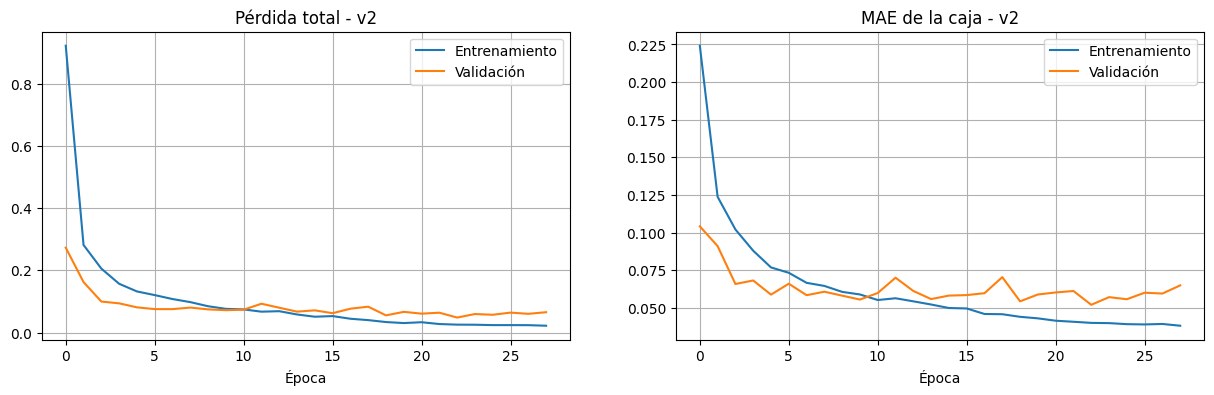

{'exactitud': 1.0,
 'MAE caja': 0.0521,
 'IoU promedio': 0.301,
 '% IoU >= 0.5': 23.5}

In [17]:
graficar(history_v2, "v2")

metricas_v2 = evaluar(model_v2, val_ds, cajas_val, auto_val)
metricas_v2

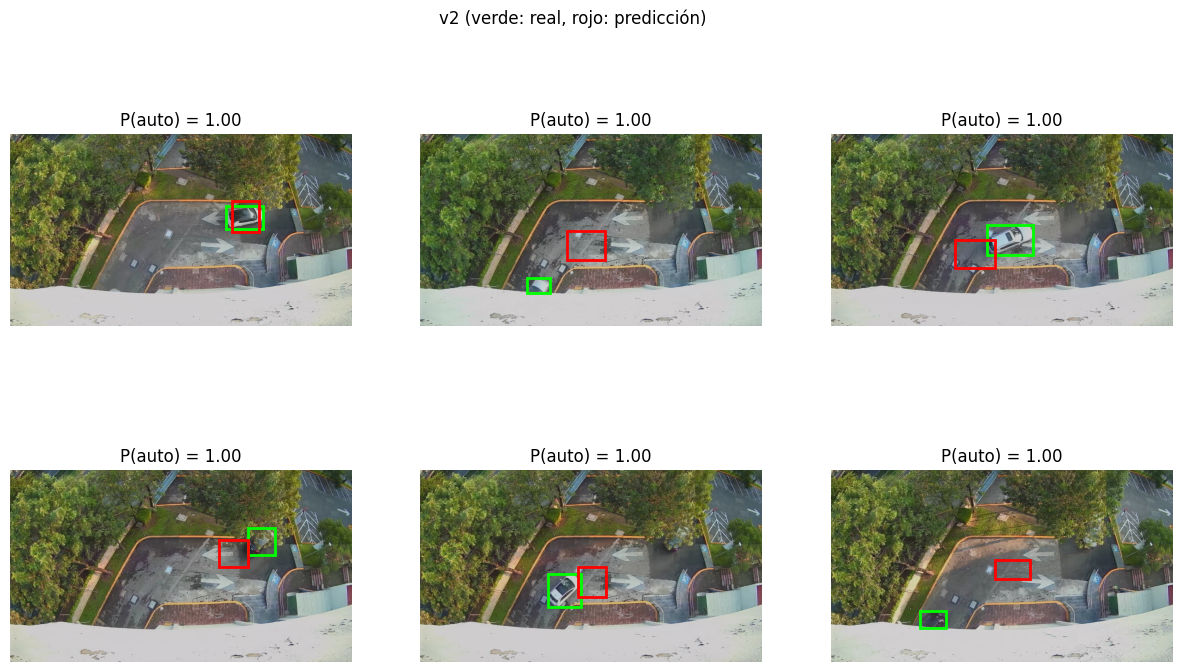

In [18]:
mostrar_predicciones(model_v2, rutas_val, cajas_val, auto_val, "v2")

### Comparación de versiones

In [19]:
comparacion = pd.DataFrame({"v1": metricas_v1, "v2": metricas_v2}).T
comparacion

,exactitud,MAE caja,IoU promedio,% IoU >= 0.5
v1,1.0,0.0468,0.312,21.5
v2,1.0,0.0521,0.301,23.5


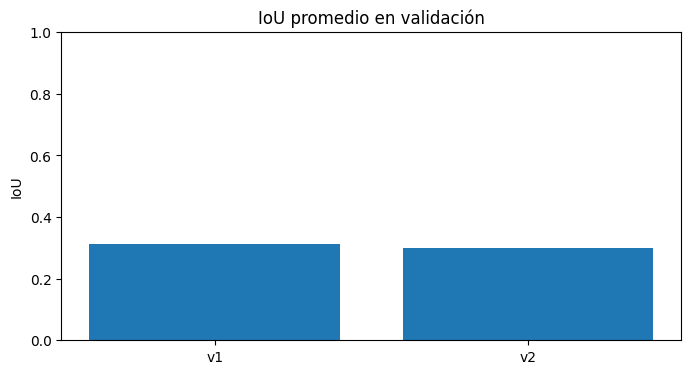

In [20]:
plt.figure(figsize=(8, 4))
plt.bar(comparacion.index, comparacion["IoU promedio"])
plt.title("IoU promedio en validación")
plt.ylabel("IoU")
plt.ylim(0, 1)
plt.show()

Las dos versiones quedaron casi iguales. v1 tiene mejor IoU promedio (0.312 contra 0.301) y v2 tiene más cajas con IoU ≥ 0.5 (23.5% contra 21.5%). La diferencia es muy chica para decir que una es mejor que la otra.

v2 no mejoró como se esperaba. La pérdida de entrenamiento siguió bajando, pero la de validación se quedó alrededor de 0.06 desde la época 10, así que también se sobreajusta. Una posible razón es que los filtros de ImageNet congelados no están hechos para ubicar con precisión un objeto chico visto desde arriba.

## 5. Resultados

Se usa la versión con mejor IoU promedio en validación y se evalúa con el conjunto de prueba.

In [21]:
mejor = "v1" if metricas_v1["IoU promedio"] >= metricas_v2["IoU promedio"] else "v2"
print("Mejor versión:", mejor)

# Sin el optimizador para que el archivo pese menos
modelo_final = tf.keras.models.load_model(f"modelos/{mejor}.keras", compile=False)
modelo_final.save("modelos/detector_autos.keras")

metricas_test = evaluar(modelo_final, test_ds, cajas_test, auto_test)
metricas_test

Mejor versión: v1


{'exactitud': 1.0,
 'MAE caja': 0.0481,
 'IoU promedio': 0.312,
 '% IoU >= 0.5': 26.8}

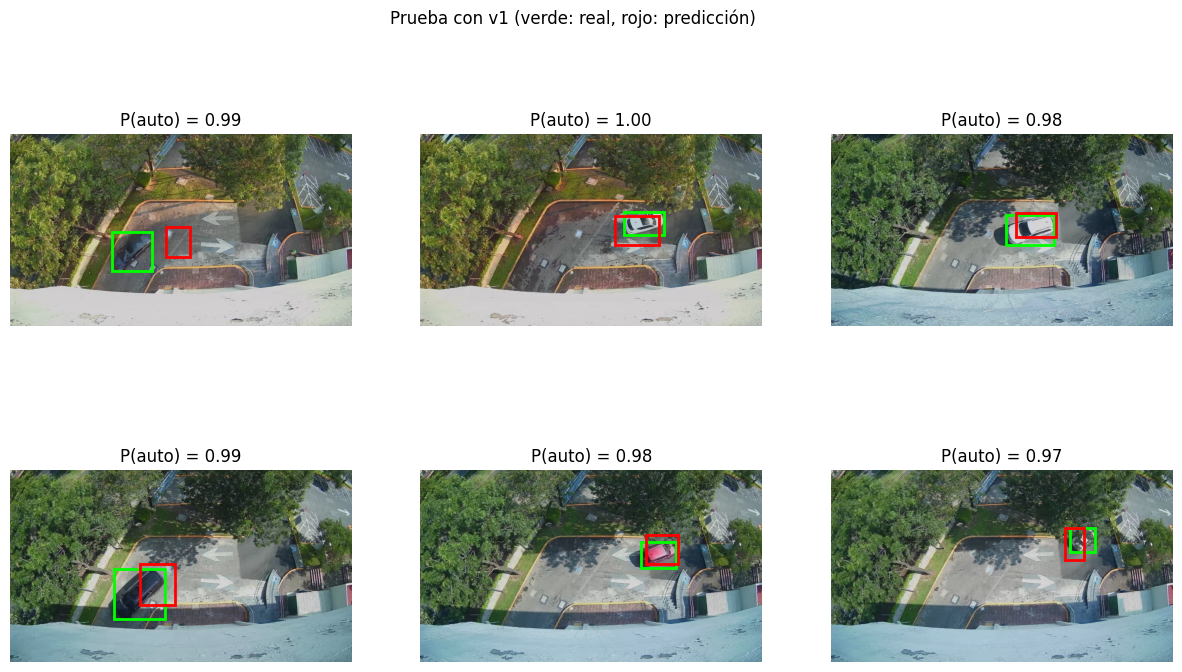

In [22]:
mostrar_predicciones(modelo_final, rutas_test, cajas_test, auto_test, f"Prueba con {mejor}")

En prueba v1 obtuvo un IoU promedio de 0.312, 26.8% de cajas con IoU ≥ 0.5 y un MAE de 0.048. El MAE parece bajo, pero un auto ocupa más o menos una décima parte del ancho de la imagen, así que un error de 0.048 es casi la mitad del auto. Por eso el IoU sale bajo. En los ejemplos el modelo encuentra la zona del auto, pero la caja queda corrida.

## 6. Conclusiones

El mejor modelo fue v1, con un IoU promedio de 0.312 en prueba. El modelo aprende en qué zona suele estar el auto, pero no lo ubica con precisión: solo una de cada cuatro cajas tiene IoU ≥ 0.5. El transfer learning y el aumento de datos no mejoraron los resultados en este caso.

Limitaciones:

- Solo predice una caja, por eso se quitaron las 190 fotos con varios autos.
- Solo hay 7 fotos sin auto y todas quedaron en entrenamiento, así que la exactitud de 1.0 en validación y prueba no dice si el modelo reconoce una zona vacía.
- Las dos versiones se sobreajustan con 693 fotos de entrenamiento.

Como trabajo futuro: usar un detector de varios objetos, por ejemplo uno tipo CenterNet que predice un mapa de calor con el centro de cada auto; agregar fotos vacías y de otras cámaras; y hacer fine-tuning de las últimas capas de MobileNetV2.

## 7. Aplicación

`detectar_auto(ruta)` muestra la imagen con la caja y regresa la probabilidad de que haya un auto y la caja en pixeles, o `None` si no detecta auto.

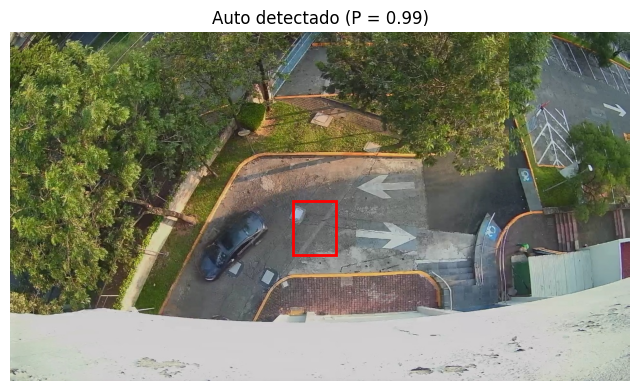

(0.9898554682731628, array([583, 347, 672, 459]))

In [24]:
detector = tf.keras.models.load_model("modelos/detector_autos.keras", compile=False)

def detectar_auto(ruta_imagen, umbral=0.5):
    prob, caja = predecir(detector, str(ruta_imagen))
    img = plt.imread(str(ruta_imagen))
    H, W = img.shape[:2]

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)
    ax.axis("off")

    if prob < umbral:
        ax.set_title(f"No se detectó auto (P = {prob:.2f})")
        plt.show()
        return prob, None

    dibujar_caja(ax, caja, W, H, "red")
    ax.set_title(f"Auto detectado (P = {prob:.2f})")
    plt.show()
    caja_px = (caja * [W, H, W, H]).astype(int)
    return prob, caja_px

detectar_auto(rutas_test[0])

## Referencias

- Notebooks del curso: `04_Data_Augmentation_with_Keras` y `08_Custom_Layers_and_Transfer_Learning`.